In [ ]:
## Sentiment Analysis - Finance Tweets
## Comparison of ML. FinBERT and Ensemble Models

In [1]:
# Force CPU usage (globally)

import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = ""

In [67]:
# Imports & Config

import pandas as pd
import numpy as np
import torch
import re
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

SEED = 42
torch.manual_seed(SEED)

# Explicitly set device to CPU
device = torch.device("cpu")

In [68]:
# Load Clean Data

data = pd.read_csv(
    "~/Documents/Datasets/data_sentiment.csv",
    encoding="utf-8"   
)

# Drop duplicates
data = data.drop_duplicates(subset="Sentence")

# Fix corrupted rows
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    
    return text.strip()

data["Sentence"] = data["Sentence"].apply(clean_text)

# Remove empty rows
data = data[data["Sentence"].str.split().str.len() > 2]

In [69]:
data.head()

,Sentence,Sentiment
0,The GeoSolutions technology will leverage Bene...,positive
1,"$ESI on lows, down $1.50 to $2.50 BK a real po...",negative
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,According to the Finnish-Russian Chamber of Co...,neutral
4,The Swedish buyout firm has sold its remaining...,neutral


In [70]:
# Label Encoding
label_map = {"negative": 0, "neutral": 1, "positive": 2}
data["label"] = data["Sentiment"].map(label_map)

# reverses the mapping
id2label = {v: k for k, v in label_map.items()}

In [63]:
# Train / Valid / Test Split

X = data["Sentence"].tolist()
y = data["label"].tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED
)

In [66]:
## class balance in training data

train_counts = pd.Series(y_train).value_counts()
print(train_counts)

(train_counts / train_counts.sum() * 100).round(2)

1    1726
2    1109
0     354
Name: count, dtype: int64


1    54.12
2    34.78
0    11.10
Name: count, dtype: float64

In [75]:
# Class Weights (to address class imbalance in training data)
# weight = total_samples / (num_classes * samples_in_class)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

In [8]:
# Load FinBert 

model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label_map
)

model = model.to(device)

/opt/anaconda3/envs/finbert_env/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/opt/anaconda3/envs/finbert_env/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [9]:
# Tokenization 

## batch size ≈ 1000 (huggingface default)
## tokenizer returns token_ids and attention masks

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=256
    )

In [10]:
# Convert to Dataset

from datasets import Dataset

train_dataset = Dataset.from_dict({"text": X_train, "label": y_train})
valid_dataset = Dataset.from_dict({"text": X_valid, "label": y_valid})
test_dataset  = Dataset.from_dict({"text": X_test,  "label": y_test})

train_dataset = train_dataset.map(tokenize, batched=True)
valid_dataset = valid_dataset.map(tokenize, batched=True)
test_dataset  = test_dataset.map(tokenize, batched=True)

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "label"])
valid_dataset.set_format("torch", columns=["input_ids", "attention_mask", "label"])
test_dataset.set_format("torch", columns=["input_ids", "attention_mask", "label"])

Map:   0%|          | 0/3193 [00:00<?, ? examples/s]

Map:   0%|          | 0/1064 [00:00<?, ? examples/s]

Map:   0%|          | 0/1065 [00:00<?, ? examples/s]

In [11]:
# Custom Trainer (with class weights)

from torch.nn import CrossEntropyLoss

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        weights = class_weights.to(logits.device)  # still needed
        
        loss_fct = CrossEntropyLoss(weight=weights)
        loss = loss_fct(logits, labels)
        
        return (loss, outputs) if return_outputs else loss

In [12]:
# Metrics 

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    
    return {
        "accuracy": (preds == labels).mean()
    }

In [13]:
# Training Arguments

training_args = TrainingArguments(
    output_dir="./finbert_model",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_dir="./logs",
    fp16=False,
    report_to="none"
)

In [14]:
# Train 

from transformers import DataCollatorWithPadding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    compute_metrics=compute_metrics,
    data_collator=data_collator, 
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.590529,0.832707
2,0.598200,0.649063,0.838346
3,0.242800,0.787285,0.837406


TrainOutput(global_step=1200, training_loss=0.3790797805786133, metrics={'train_runtime': 160.9943, 'train_samples_per_second': 59.499, 'train_steps_per_second': 7.454, 'total_flos': 251001464324814.0, 'train_loss': 0.3790797805786133, 'epoch': 3.0})


Train Results:
              precision    recall  f1-score   support

    negative       0.83      0.66      0.73       355
     neutral       0.91      0.96      0.93      1727
    positive       0.95      0.92      0.93      1111

    accuracy                           0.91      3193
   macro avg       0.89      0.85      0.87      3193
weighted avg       0.91      0.91      0.91      3193



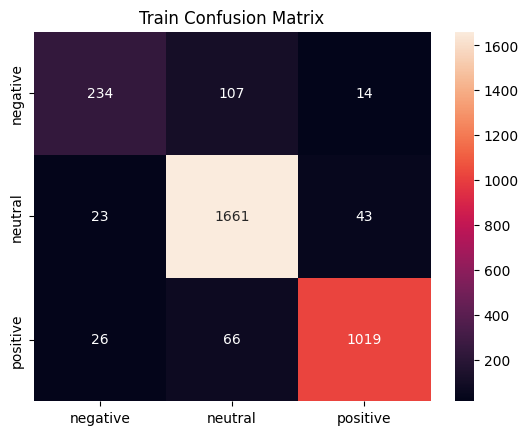


Validation Results:
              precision    recall  f1-score   support

    negative       0.63      0.46      0.53       119
     neutral       0.85      0.92      0.88       575
    positive       0.86      0.82      0.84       370

    accuracy                           0.83      1064
   macro avg       0.78      0.73      0.75      1064
weighted avg       0.83      0.83      0.83      1064



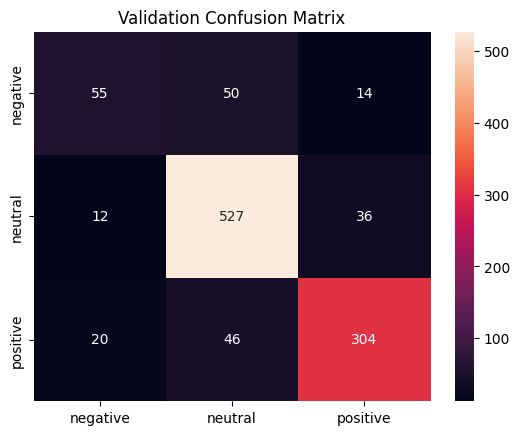


Test Results:
              precision    recall  f1-score   support

    negative       0.71      0.47      0.57       118
     neutral       0.87      0.93      0.90       576
    positive       0.86      0.86      0.86       371

    accuracy                           0.85      1065
   macro avg       0.81      0.75      0.77      1065
weighted avg       0.85      0.85      0.85      1065



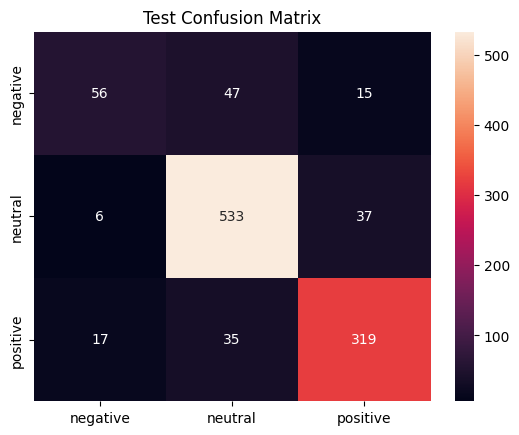

In [15]:
# Evaluation 

def evaluate(dataset, y_true, name):
    preds = trainer.predict(dataset)
    y_pred = np.argmax(preds.predictions, axis=1)
    
    print(f"\n{name} Results:")
    print(classification_report(y_true, y_pred, target_names=id2label.values()))
    
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=id2label.values(), yticklabels=id2label.values())
    plt.title(f"{name} Confusion Matrix")
    plt.show()

evaluate(train_dataset, y_train, "Train")
evaluate(valid_dataset, y_valid, "Validation")
evaluate(test_dataset, y_test, "Test")

In [16]:
# Inference (Robust)

def predict(texts):
    model.eval()
    
    texts = [t if isinstance(t, str) else "" for t in texts]
    
    inputs = tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)
    
    with torch.no_grad():
        logits = model(**inputs).logits
    
    probs = torch.softmax(logits, dim=1).cpu().numpy()
    preds = probs.argmax(axis=1)
    
    return [id2label[p] for p in preds], probs

In [ ]:
# classical ML model

In [17]:
# Classical ML Pipeline

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Build pipeline
ml_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1,2),
        stop_words="english"
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train
ml_pipeline.fit(X_train, y_train)

,steps,"[('tfidf', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None



Train Results (Classical ML):
              precision    recall  f1-score   support

    negative       0.91      1.00      0.95       355
     neutral       0.99      0.96      0.98      1727
    positive       0.97      0.99      0.98      1111

    accuracy                           0.98      3193
   macro avg       0.96      0.98      0.97      3193
weighted avg       0.98      0.98      0.98      3193



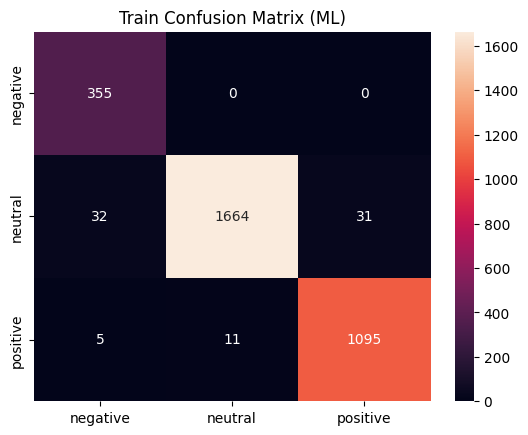


Validation Results (Classical ML):
              precision    recall  f1-score   support

    negative       0.50      0.46      0.48       119
     neutral       0.77      0.82      0.79       575
    positive       0.68      0.62      0.65       370

    accuracy                           0.71      1064
   macro avg       0.65      0.64      0.64      1064
weighted avg       0.71      0.71      0.71      1064



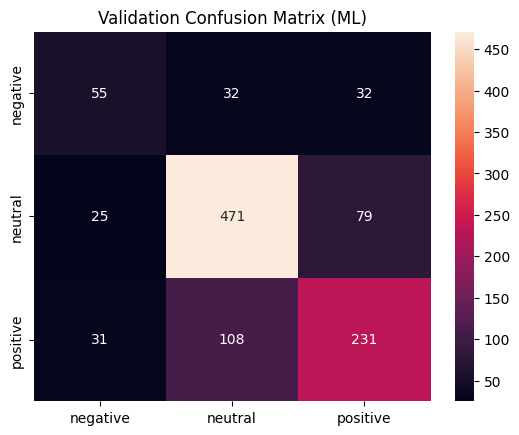


Test Results (Classical ML):
              precision    recall  f1-score   support

    negative       0.46      0.45      0.45       118
     neutral       0.78      0.82      0.80       576
    positive       0.70      0.66      0.68       371

    accuracy                           0.72      1065
   macro avg       0.65      0.64      0.64      1065
weighted avg       0.72      0.72      0.72      1065



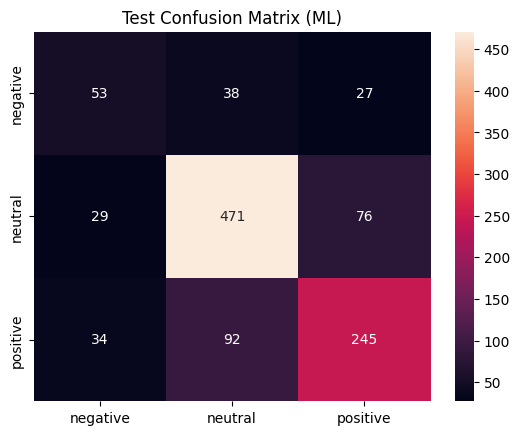

In [18]:
## ML evaluation 

# Cell: Evaluate classical model

def evaluate_ml(model, X, y, name):
    preds = model.predict(X)
    
    print(f"\n{name} Results (Classical ML):")
    print(classification_report(y, preds, target_names=id2label.values()))
    
    cm = confusion_matrix(y, preds)
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=id2label.values(),
                yticklabels=id2label.values())
    plt.title(f"{name} Confusion Matrix (ML)")
    plt.show()
    
    return preds

ml_train_preds = evaluate_ml(ml_pipeline, X_train, y_train, "Train")
ml_valid_preds = evaluate_ml(ml_pipeline, X_valid, y_valid, "Validation")
ml_test_preds  = evaluate_ml(ml_pipeline, X_test,  y_test,  "Test")

In [19]:
# FinBERT predictions 

def get_finbert_preds(dataset):
    preds = trainer.predict(dataset)
    return np.argmax(preds.predictions, axis=1)

bert_train_preds = get_finbert_preds(train_dataset)
bert_valid_preds = get_finbert_preds(valid_dataset)
bert_test_preds  = get_finbert_preds(test_dataset)


Train Results (FinBERT):
              precision    recall  f1-score   support

    negative       0.83      0.66      0.73       355
     neutral       0.91      0.96      0.93      1727
    positive       0.95      0.92      0.93      1111

    accuracy                           0.91      3193
   macro avg       0.89      0.85      0.87      3193
weighted avg       0.91      0.91      0.91      3193



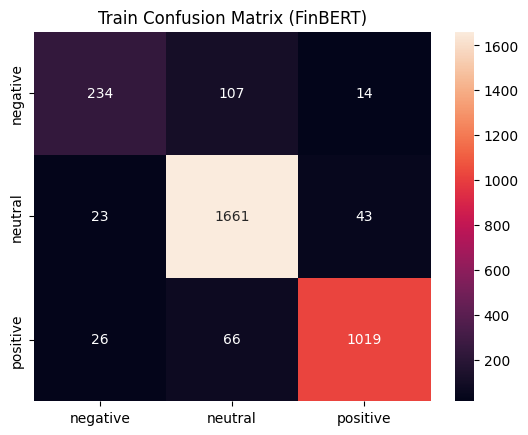


Validation Results (FinBERT):
              precision    recall  f1-score   support

    negative       0.63      0.46      0.53       119
     neutral       0.85      0.92      0.88       575
    positive       0.86      0.82      0.84       370

    accuracy                           0.83      1064
   macro avg       0.78      0.73      0.75      1064
weighted avg       0.83      0.83      0.83      1064



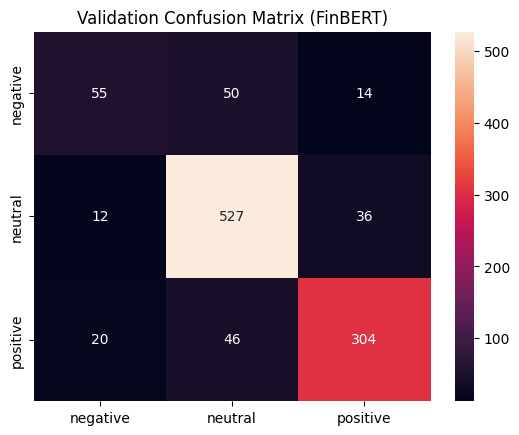


Test Results (FinBERT):
              precision    recall  f1-score   support

    negative       0.71      0.47      0.57       118
     neutral       0.87      0.93      0.90       576
    positive       0.86      0.86      0.86       371

    accuracy                           0.85      1065
   macro avg       0.81      0.75      0.77      1065
weighted avg       0.85      0.85      0.85      1065



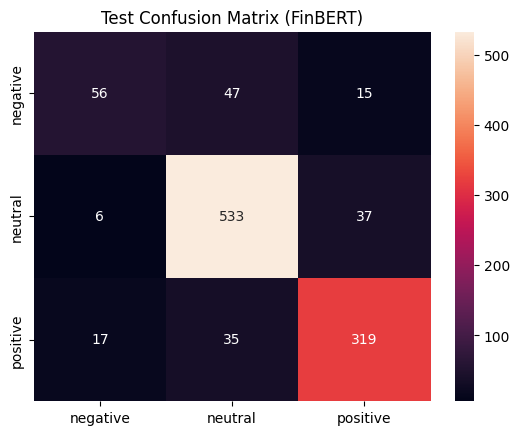

In [20]:
# Evaluate FinBERT

def evaluate_bert(y_true, y_pred, name):
    print(f"\n{name} Results (FinBERT):")
    print(classification_report(y_true, y_pred, target_names=id2label.values()))
    
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=id2label.values(),
                yticklabels=id2label.values())
    plt.title(f"{name} Confusion Matrix (FinBERT)")
    plt.show()

evaluate_bert(y_train, bert_train_preds, "Train")
evaluate_bert(y_valid, bert_valid_preds, "Validation")
evaluate_bert(y_test,  bert_test_preds,  "Test")

In [21]:
# Comparison summary

from sklearn.metrics import accuracy_score, f1_score

def summarize(y_true, ml_preds, bert_preds, name):
    return {
        "Dataset": name,
        "ML Accuracy": accuracy_score(y_true, ml_preds),
        "BERT Accuracy": accuracy_score(y_true, bert_preds),
        "ML F1": f1_score(y_true, ml_preds, average="weighted"),
        "BERT F1": f1_score(y_true, bert_preds, average="weighted")
    }

results = [
    summarize(y_train, ml_train_preds, bert_train_preds, "Train"),
    summarize(y_valid, ml_valid_preds, bert_valid_preds, "Validation"),
    summarize(y_test,  ml_test_preds,  bert_test_preds,  "Test")
]

results_df = pd.DataFrame(results)
results_df

,Dataset,ML Accuracy,BERT Accuracy,ML F1,BERT F1
0,Train,0.975258,0.912621,0.975418,0.910368
1,Validation,0.711466,0.832707,0.708365,0.827206
2,Test,0.722066,0.852582,0.720456,0.846604


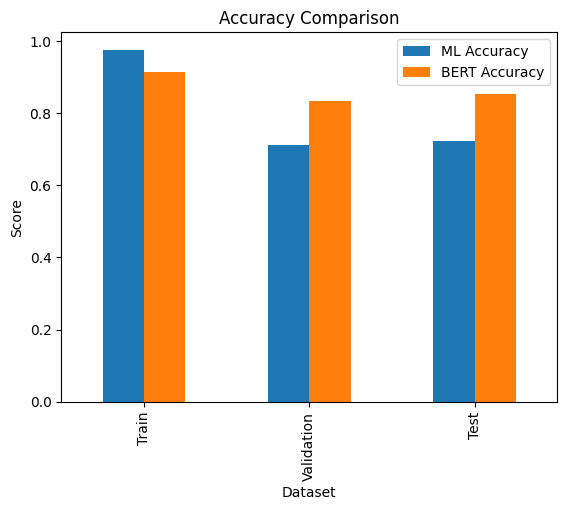

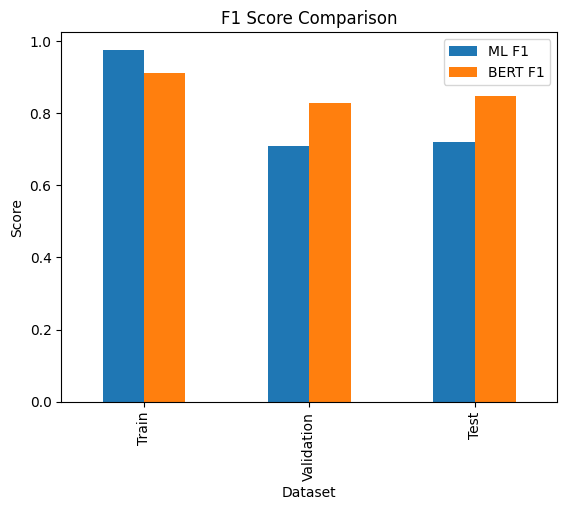

In [22]:
# Plot comparison

results_df.set_index("Dataset")[["ML Accuracy", "BERT Accuracy"]].plot(kind="bar")
plt.title("Accuracy Comparison")
plt.ylabel("Score")
plt.show()

results_df.set_index("Dataset")[["ML F1", "BERT F1"]].plot(kind="bar")
plt.title("F1 Score Comparison")
plt.ylabel("Score")
plt.show()

In [ ]:
# Ensemble Model
# Final prediction = argmax( w1 * ML_probs + w2 * BERT_probs )
## Why this works:
### ML captures surface patterns
### FinBERT captures context
### Ensemble combines both signals

In [23]:
# Modify Classical ML → return probabilities
# Get ML probabilities

def get_ml_probs(model, X):
    return model.predict_proba(X)

ml_train_probs = get_ml_probs(ml_pipeline, X_train)
ml_valid_probs = get_ml_probs(ml_pipeline, X_valid)
ml_test_probs  = get_ml_probs(ml_pipeline, X_test)

In [24]:
# Get FinBERT probabilities

def get_bert_probs(dataset):
    preds = trainer.predict(dataset)
    logits = preds.predictions
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    return probs

bert_train_probs = get_bert_probs(train_dataset)
bert_valid_probs = get_bert_probs(valid_dataset)
bert_test_probs  = get_bert_probs(test_dataset)

In [25]:
# Weighted ensemble

def ensemble_predict(ml_probs, bert_probs, w_ml=0.4, w_bert=0.6):
    combined = w_ml * ml_probs + w_bert * bert_probs
    preds = combined.argmax(axis=1)
    return preds, combined

In [26]:
# grid search for weights

best_score = 0
best_w = None

for w in np.linspace(0, 1, 11):
    preds, _ = ensemble_predict(
        ml_valid_probs,
        bert_valid_probs,
        w_ml=w,
        w_bert=1-w
    )
    
    score = f1_score(y_valid, preds, average="weighted")
    
    if score > best_score:
        best_score = score
        best_w = w

print("Best ML weight:", best_w)

Best ML weight: 0.6000000000000001


In [27]:
# best model and weight

best_w_ml = best_w
best_w_bert = 1 - best_w

In [28]:
# Ensemble Predictions with best model weights

# Train
ens_train_preds, ens_train_probs = ensemble_predict(
    ml_train_probs,
    bert_train_probs,
    w_ml=best_w_ml,
    w_bert=best_w_bert
)

# Validation
ens_valid_preds, ens_valid_probs = ensemble_predict(
    ml_valid_probs,
    bert_valid_probs,
    w_ml=best_w_ml,
    w_bert=best_w_bert
)

# Test
ens_test_preds, ens_test_probs = ensemble_predict(
    ml_test_probs,
    bert_test_probs,
    w_ml=best_w_ml,
    w_bert=best_w_bert
)


Train Results (Ensemble):
              precision    recall  f1-score   support

    negative       0.90      0.92      0.91       355
     neutral       0.96      0.97      0.96      1727
    positive       0.96      0.94      0.95      1111

    accuracy                           0.95      3193
   macro avg       0.94      0.94      0.94      3193
weighted avg       0.95      0.95      0.95      3193



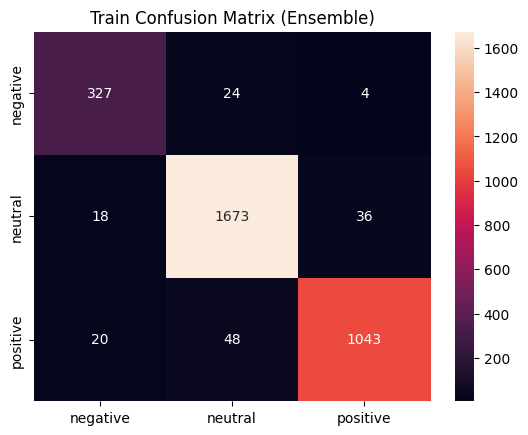


Validation Results (Ensemble):
              precision    recall  f1-score   support

    negative       0.64      0.47      0.54       119
     neutral       0.85      0.91      0.88       575
    positive       0.85      0.84      0.85       370

    accuracy                           0.84      1064
   macro avg       0.78      0.74      0.76      1064
weighted avg       0.83      0.84      0.83      1064



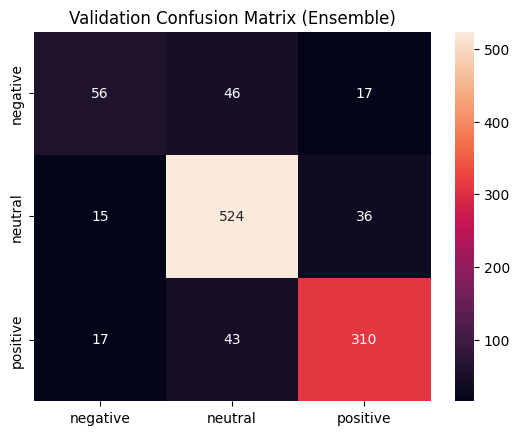


Test Results (Ensemble):
              precision    recall  f1-score   support

    negative       0.66      0.52      0.58       118
     neutral       0.87      0.91      0.89       576
    positive       0.86      0.87      0.86       371

    accuracy                           0.85      1065
   macro avg       0.80      0.76      0.78      1065
weighted avg       0.84      0.85      0.85      1065



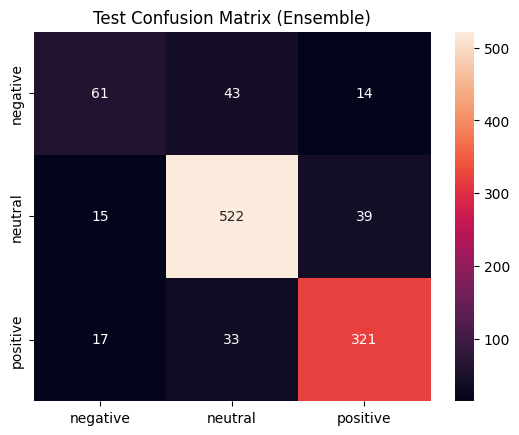

In [29]:
# evaluate ensemble

def evaluate_ensemble(y_true, y_pred, name):
    print(f"\n{name} Results (Ensemble):")
    print(classification_report(y_true, y_pred, target_names=id2label.values()))
    
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=id2label.values(),
                yticklabels=id2label.values())
    plt.title(f"{name} Confusion Matrix (Ensemble)")
    plt.show()

evaluate_ensemble(y_train, ens_train_preds, "Train")
evaluate_ensemble(y_valid, ens_valid_preds, "Validation")
evaluate_ensemble(y_test,  ens_test_preds,  "Test")

In [30]:
# Compare all three models

from sklearn.metrics import accuracy_score, f1_score

def summarize_all(y_true, ml_preds, bert_preds, ens_preds, name):
    return {
        "Dataset": name,
        "ML Acc": accuracy_score(y_true, ml_preds),
        "BERT Acc": accuracy_score(y_true, bert_preds),
        "Ensemble Acc": accuracy_score(y_true, ens_preds),
        
        "ML F1": f1_score(y_true, ml_preds, average="weighted"),
        "BERT F1": f1_score(y_true, bert_preds, average="weighted"),
        "Ensemble F1": f1_score(y_true, ens_preds, average="weighted")
    }

results = [
    summarize_all(y_train, ml_train_preds, bert_train_preds, ens_train_preds, "Train"),
    summarize_all(y_valid, ml_valid_preds, bert_valid_preds, ens_valid_preds, "Validation"),
    summarize_all(y_test,  ml_test_preds,  bert_test_preds,  ens_test_preds,  "Test")
]

results_df = pd.DataFrame(results)
results_df

,Dataset,ML Acc,BERT Acc,Ensemble Acc,ML F1,BERT F1,Ensemble F1
0,Train,0.975258,0.912621,0.953022,0.975418,0.910368,0.953052
1,Validation,0.711466,0.832707,0.836466,0.708365,0.827206,0.831378
2,Test,0.722066,0.852582,0.848826,0.720456,0.846604,0.845214


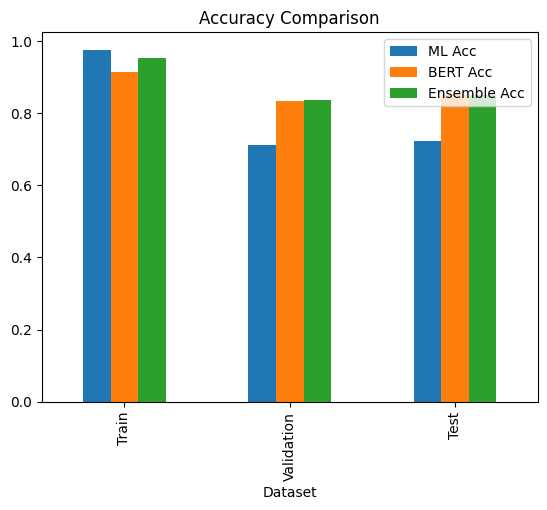

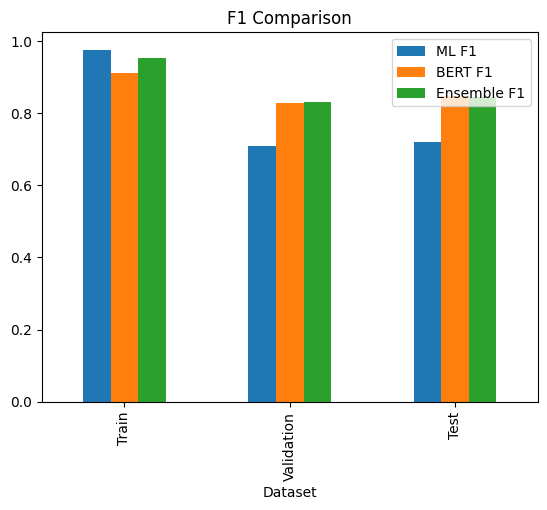

In [31]:
# Visulalization of Results 

results_df.set_index("Dataset")[["ML Acc", "BERT Acc", "Ensemble Acc"]].plot(kind="bar")
plt.title("Accuracy Comparison")
plt.show()

results_df.set_index("Dataset")[["ML F1", "BERT F1", "Ensemble F1"]].plot(kind="bar")
plt.title("F1 Comparison")
plt.show()

In [ ]:
# evaluation dashboard

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [33]:
def compute_all_metrics(y_true, preds, probs):
    return {
        "accuracy": accuracy_score(y_true, preds),
        "f1_macro": f1_score(y_true, preds, average="macro"),
        "f1_weighted": f1_score(y_true, preds, average="weighted"),
        "roc_auc": roc_auc_score(y_true, probs, multi_class="ovr")
    }

In [34]:
def build_metrics_table():
    rows = []

    for name, preds, probs in [
        ("ML", ml_test_preds, ml_test_probs),
        ("FinBERT", bert_test_preds, bert_test_probs),
        ("Ensemble", ens_test_preds, ens_test_probs)
    ]:
        m = compute_all_metrics(y_test, preds, probs)
        m["model"] = name
        rows.append(m)

    df = pd.DataFrame(rows).set_index("model")
    return df

metrics_df = build_metrics_table()
metrics_df

,accuracy,f1_macro,f1_weighted,roc_auc
model,,,,
ML,0.722066,0.644944,0.720456,0.848829
FinBERT,0.852582,0.774471,0.846604,0.954481
Ensemble,0.848826,0.776404,0.845214,0.943551


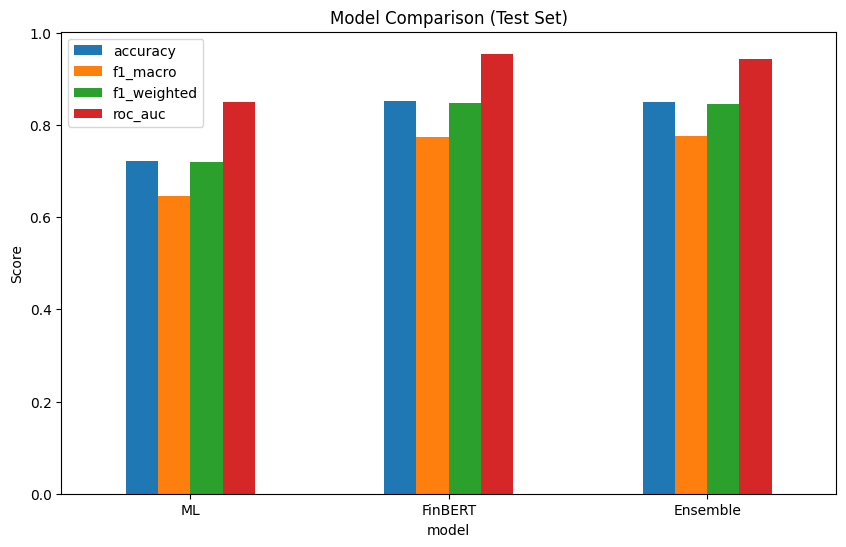

In [35]:
metrics_df.plot(kind="bar", figsize=(10,6))
plt.title("Model Comparison (Test Set)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

In [36]:
## evaluate class wise 

def classwise_table():
    tables = []
    
    for name, preds in [
        ("ML", ml_test_preds),
        ("FinBERT", bert_test_preds),
        ("Ensemble", ens_test_preds)
    ]:
        report = classification_report(
            y_test, preds,
            target_names=id2label.values(),
            output_dict=True
        )
        df = pd.DataFrame(report).T
        df["model"] = name
        tables.append(df)
    
    return pd.concat(tables)

classwise_df = classwise_table()
classwise_df

,precision,recall,f1-score,support,model
negative,0.456897,0.449153,0.452991,118.000000,ML
neutral,0.783694,0.817708,0.800340,576.000000,ML
positive,0.704023,0.660377,0.681502,371.000000,ML
accuracy,0.722066,0.722066,0.722066,0.722066,ML
macro avg,0.648204,0.642413,0.644944,1065.000000,ML
weighted avg,0.719731,0.722066,0.720456,1065.000000,ML
negative,0.708861,0.474576,0.568528,118.000000,FinBERT
neutral,0.866667,0.925347,0.895046,576.000000,FinBERT
positive,0.859838,0.859838,0.859838,371.000000,FinBERT
accuracy,0.852582,0.852582,0.852582,0.852582,FinBERT


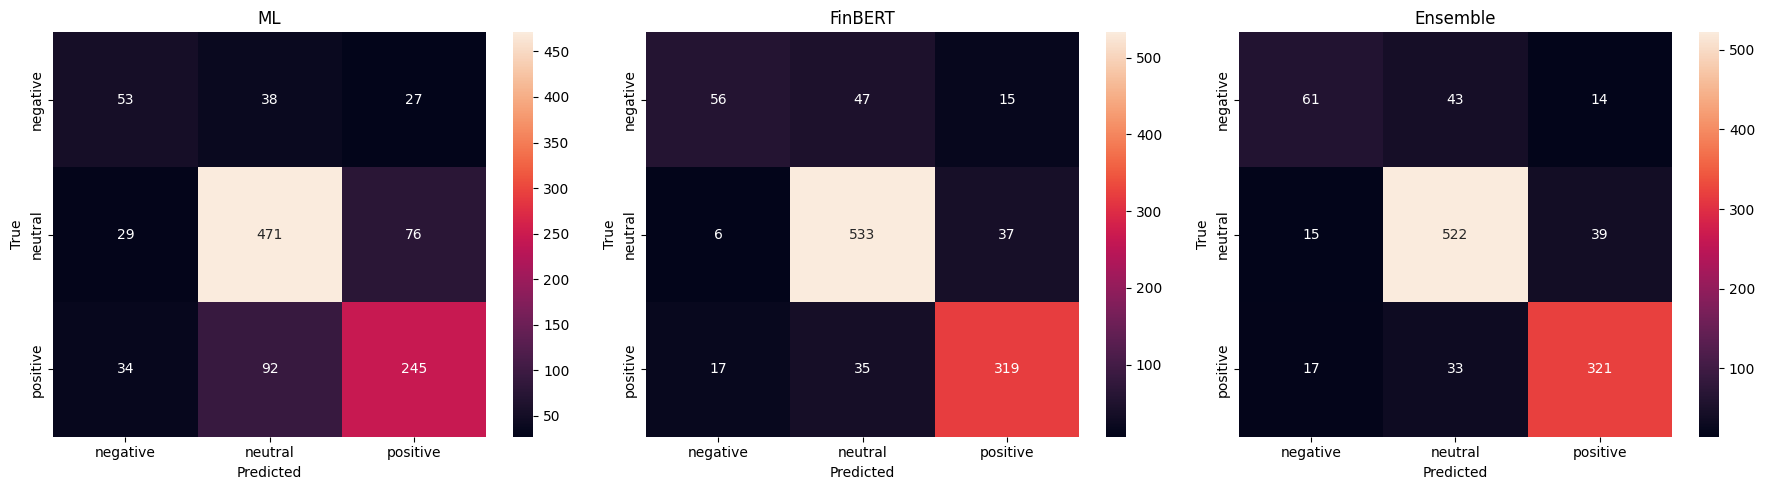

In [37]:
## plot all confusion matrices

def plot_confusion_all():
    models = [
        ("ML", ml_test_preds),
        ("FinBERT", bert_test_preds),
        ("Ensemble", ens_test_preds)
    ]
    
    fig, axes = plt.subplots(1, 3, figsize=(18,5))
    
    for ax, (name, preds) in zip(axes, models):
        cm = confusion_matrix(y_test, preds)
        sns.heatmap(cm, annot=True, fmt="d",
                    xticklabels=id2label.values(),
                    yticklabels=id2label.values(),
                    ax=ax)
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    
    plt.tight_layout()
    plt.show()

plot_confusion_all()

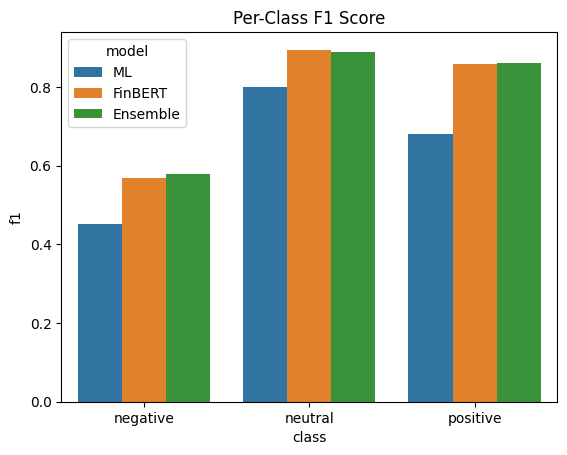

In [38]:
## plot F-1 by class

def plot_per_class_f1():
    labels = list(id2label.values())
    
    data = []
    
    for name, preds in [
        ("ML", ml_test_preds),
        ("FinBERT", bert_test_preds),
        ("Ensemble", ens_test_preds)
    ]:
        report = classification_report(
            y_test, preds,
            target_names=labels,
            output_dict=True
        )
        
        for label in labels:
            data.append({
                "model": name,
                "class": label,
                "f1": report[label]["f1-score"]
            })
    
    df = pd.DataFrame(data)
    
    sns.barplot(data=df, x="class", y="f1", hue="model")
    plt.title("Per-Class F1 Score")
    plt.show()

plot_per_class_f1()

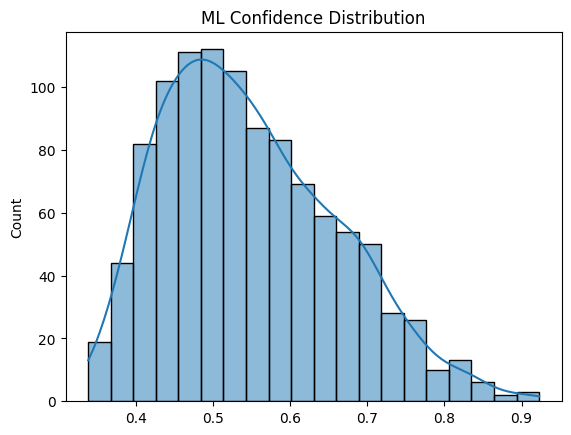

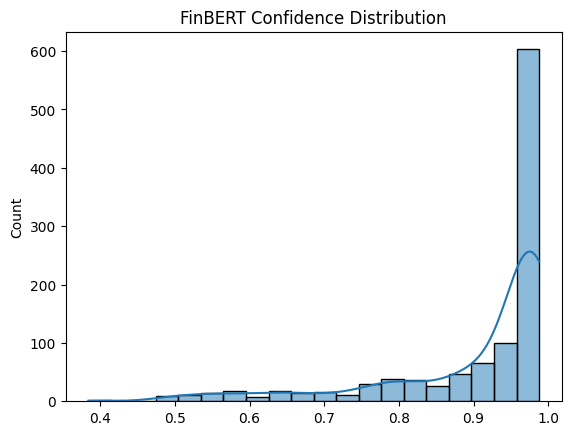

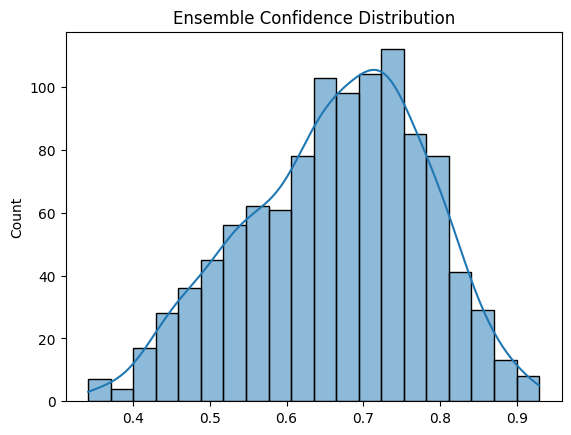

In [39]:
# confidence distribution graphs

def plot_confidence(probs, name):
    confidences = probs.max(axis=1)
    sns.histplot(confidences, bins=20, kde=True)
    plt.title(f"{name} Confidence Distribution")
    plt.show()

plot_confidence(ml_test_probs, "ML")
plot_confidence(bert_test_probs, "FinBERT")
plot_confidence(ens_test_probs, "Ensemble")

In [ ]:
## calibration curve

In [40]:
from sklearn.calibration import calibration_curve

In [45]:
def get_confidence_and_correct(probs, y_true):
    preds = np.argmax(probs, axis=1)
    confidences = np.max(probs, axis=1)
    correct = (preds == y_true).astype(int)
    return confidences, correct

In [46]:
def plot_calibration(probs, y_true, label, n_bins=10):
    conf, correct = get_confidence_and_correct(probs, y_true)
    
    frac_pos, mean_pred = calibration_curve(correct, conf, n_bins=n_bins)
    
    plt.plot(mean_pred, frac_pos, marker='o', label=label)

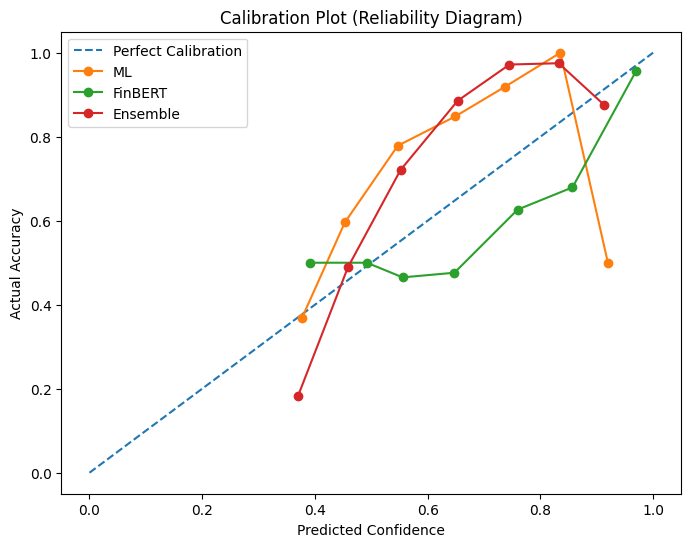

In [47]:
plt.figure(figsize=(8,6))

# Perfect calibration line
plt.plot([0,1], [0,1], linestyle='--', label='Perfect Calibration')

plot_calibration(ml_test_probs, y_test, "ML")
plot_calibration(bert_test_probs, y_test, "FinBERT")
plot_calibration(ens_test_probs, y_test, "Ensemble")

plt.xlabel("Predicted Confidence")
plt.ylabel("Actual Accuracy")
plt.title("Calibration Plot (Reliability Diagram)")
plt.legend()
plt.show()